In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

from shapely.geometry import box

poblacion_geo = gpd.read_file(
    "../Data/Procesados/poblacion_geo.gpkg"
)

print(poblacion_geo.shape)
print(poblacion_geo.crs)

(66449, 3)
EPSG:32614


In [2]:
# Tamaño de cada cuadrícula, en metros
lado = 250

# Extensión geográfica del dataset
xmin, ymin, xmax, ymax = poblacion_geo.total_bounds

# Coordenadas donde comenzará cada cuadrícula
xs = np.arange(
    np.floor(xmin / lado) * lado,
    xmax,
    lado
)

ys = np.arange(
    np.floor(ymin / lado) * lado,
    ymax,
    lado
)

# Construcción de las cuadrículas
cuadriculas = gpd.GeoDataFrame(
    geometry=[
        box(x, y, x + lado, y + lado)
        for x in xs
        for y in ys
    ],
    crs=poblacion_geo.crs
)

cuadriculas["id_celda"] = np.arange(len(cuadriculas))

print("Cuadrículas generadas:", len(cuadriculas))

Cuadrículas generadas: 34104


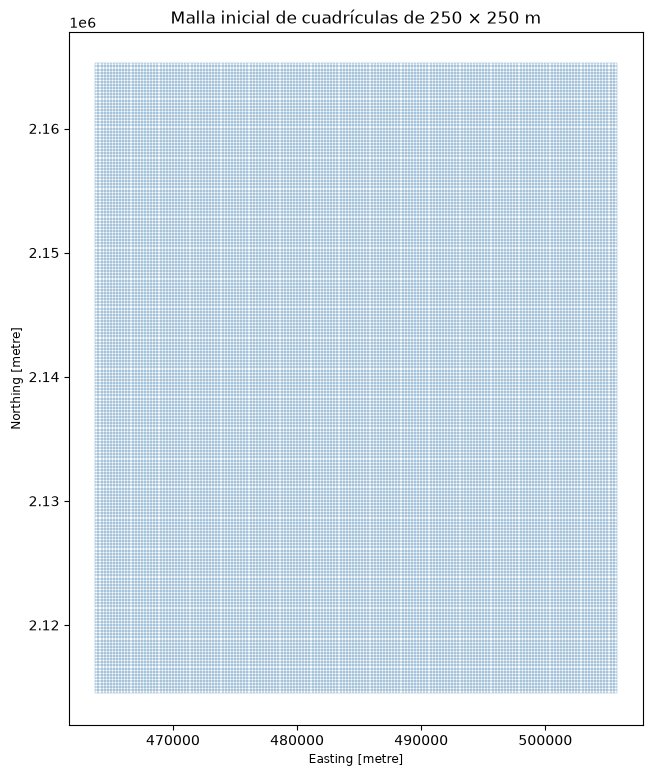

In [3]:
cuadriculas.plot(
    figsize=(9, 9),
    facecolor="none",
    edgecolor="steelblue",
    linewidth=0.2
)

plt.title("Malla inicial de cuadrículas de 250 × 250 m")
plt.show()

In [4]:
# Identificar cuadrículas que intersectan manzanas urbanas
cuadriculas_urbanas = gpd.sjoin(
    cuadriculas,
    poblacion_geo[["geometry"]],
    how="inner",
    predicate="intersects"
)

# Una cuadrícula puede intersectar varias manzanas
cuadriculas_urbanas = (
    cuadriculas_urbanas
    .loc[lambda df: ~df.index.duplicated()]
    .drop(columns="index_right")
    .reset_index(drop=True)
)

print("Cuadrículas originales:", len(cuadriculas))
print("Cuadrículas urbanas:", len(cuadriculas_urbanas))
print("Cuadrículas excluidas:",
      len(cuadriculas) - len(cuadriculas_urbanas))


Cuadrículas originales: 34104
Cuadrículas urbanas: 13543
Cuadrículas excluidas: 20561


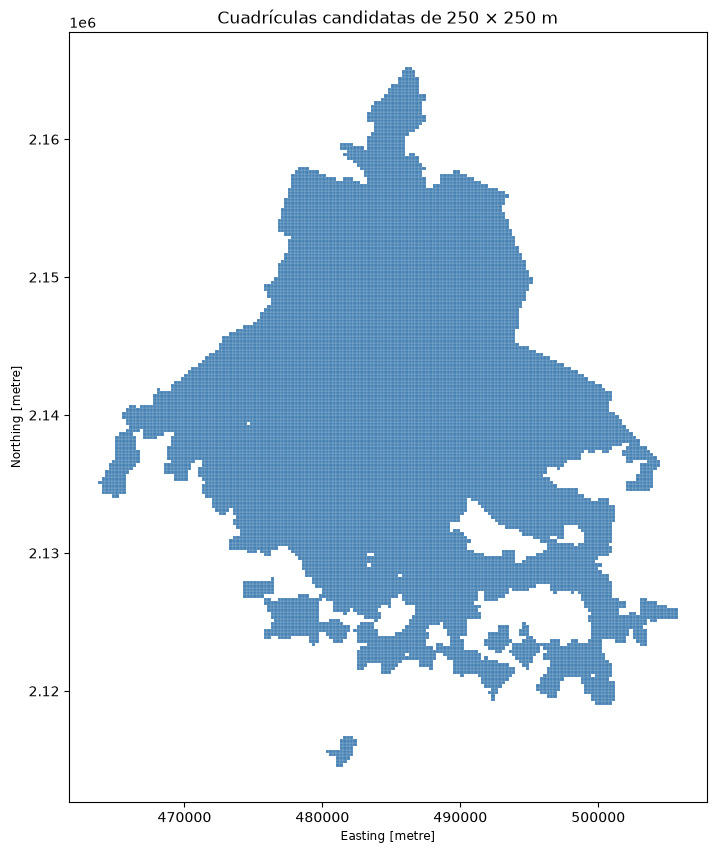

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10))

cuadriculas_urbanas.plot(
    ax=ax,
    facecolor="steelblue",
    edgecolor="white",
    linewidth=0.1
)

ax.set_title("Cuadrículas candidatas de 250 × 250 m")
plt.show()


In [6]:
cuadriculas_urbanas["centro_x"] = cuadriculas_urbanas.centroid.x
cuadriculas_urbanas["centro_y"] = cuadriculas_urbanas.centroid.y

cuadriculas_urbanas[
    ["id_celda", "centro_x", "centro_y"]
].head()

,id_celda,centro_x,centro_y
0,82,463875.0,2135125.0
1,282,464125.0,2134375.0
2,283,464125.0,2134625.0
3,284,464125.0,2134875.0
4,285,464125.0,2135125.0


In [7]:
cuadriculas_urbanas.to_file(
    "../Data/Procesados/cuadriculas_candidatas.gpkg",
    driver="GPKG"
)

### Conclusiones — Construcción de zonas candidatas

Se construyó una malla geográfica regular de 250 × 250 metros utilizando el sistema de coordenadas EPSG:32614.

Inicialmente se generaron 34,104 cuadrículas, de las cuales se conservaron 13,543 que intersectan al menos una manzana urbana de los datos del INEGI.

Estas cuadrículas constituyen el conjunto preliminar de zonas candidatas para la expansión de ECOBICI.

**Limitación:** el criterio de intersección con manzanas urbanas no garantiza la viabilidad física de instalación de una estación. Esta restricción deberá considerarse en la interpretación de las recomendaciones finales.